# 06 — CNN vs classical models

This notebook brings together the two families of models trained in the project:

- **classical models** on 155 hand-crafted features (`src/experiments_classic.py`, analysed in `04_classic_experiments.ipynb`): chance level (`dummy`), logistic regression, SVM, Random Forest and their majority vote;
- **CNN** on Mel-spectrograms (`src/train_cnn.py`, decisions D16 and D17): three variants compared on protocol A, the variant chosen on validation (`small`) evaluated on the five artist-grouped splits.

The questions are: is the CNN better than the classical models, is the difference larger than the variation between splits, is it statistically significant, and where (which quadrants, which genres) does it come from?

Nothing is trained here. The notebook reads `results/experiments/` and `results/cnn/` and writes its tables and figures to `results/comparison/`. As in the rest of the project, all choices were made on validation; test scores are only reported. The classical models used for the comparison are the ones with the tonal feature set (155 features), which was kept in D13.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import confusion_matrix, f1_score

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
EXP = ROOT / "results" / "experiments"
CNN_DIR = ROOT / "results" / "cnn"
OUT = ROOT / "results" / "comparison"
OUT.mkdir(parents=True, exist_ok=True)
META = ROOT / "data" / "raw" / "MERGE_Audio_Balanced" / "merge_audio_balanced_metadata.csv"

QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
NAMES = {"Q1": "Q1 happy", "Q2": "Q2 angry/tense", "Q3": "Q3 sad", "Q4": "Q4 calm"}
B_SPLITS = ["B42", "B43", "B44", "B45", "B46"]
COLORS = {"dummy": "#999999", "logreg": "#56B4E9", "svm": "#0072B2", "rf": "#009E73", "vote": "#E69F00", "cnn": "#CC79A7"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})
summary = {}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()


cnn_rows = []
for path in sorted(CNN_DIR.glob("*_cnn_*/metrics.json")):
    m = json.loads(path.read_text(encoding="utf-8"))
    cnn_rows.append({"folder": path.parent.name, "config": m["config"], "protocol": m["protocol"], "parameters": m["parameters"],
                     "best_epoch": m["best_epoch"], "epochs_run": m["epochs_run"], "train_macro_f1": m["train_macro_f1"],
                     "val_macro_f1": m["validation_macro_f1"], "test_macro_f1": m["test_macro_f1"], "test_accuracy": m["test_accuracy"],
                     **{f"test_f1_{q}": m["test_f1_per_class"][q] for q in QUADRANTS},
                     "test_q3_q4": m["test_q3_q4_confusions"], "train_seconds": m["train_seconds"],
                     "seconds_per_epoch": m["seconds_per_epoch"], "model_mb": m["model_mb"]})
cnn = pd.DataFrame(cnn_rows).sort_values("folder").drop_duplicates(["config", "protocol"], keep="last").reset_index(drop=True)

runs = pd.read_csv(EXP / "runs.csv")
classic = runs[runs.feature_set == "tonal"].copy()
classic["test_q3_q4"] = classic["test_q3_as_q4"] + classic["test_q4_as_q3"]

preds = pd.read_csv(EXP / "test_predictions.csv", dtype={"Song": str})
preds = preds[preds.feature_set == "tonal"][["protocol", "model", "Song", "true", "pred"]]
cnn_preds = []
for r in cnn.itertuples():
    p = pd.read_csv(CNN_DIR / r.folder / "test_predictions.csv", dtype={"Song": str})
    cnn_preds.append(p.assign(protocol=r.protocol, model="cnn" if r.config == "small" else f"cnn_{r.config}"))
cnn_preds = pd.concat(cnn_preds)
all_preds = pd.concat([preds, cnn_preds[["protocol", "model", "Song", "true", "pred"] + [f"prob_{q}" for q in QUADRANTS]]])

done = [s for s in B_SPLITS if ((cnn.config == "small") & (cnn.protocol == s)).any()]
summary["cnn_B_splits_available"] = done
print("CNN runs found:")
cnn[["config", "protocol", "best_epoch", "epochs_run", "val_macro_f1", "test_macro_f1", "folder"]]

CNN runs found:


,config,protocol,best_epoch,epochs_run,val_macro_f1,test_macro_f1,folder
0,small,A,60,60,0.7233,0.6816,20261121_193756_cnn_small_A
1,fast,A,57,60,0.7017,0.6859,20261121_222524_cnn_fast_A
2,fast_aug,A,36,48,0.6883,0.6685,20261121_222524_cnn_fast_aug_A
3,small,B42,28,40,0.7247,0.7012,20261122_122104_cnn_small_B42
4,small,B43,51,60,0.7427,0.6856,20261122_122104_cnn_small_B43
5,small,B44,34,46,0.7337,0.6655,20261122_122104_cnn_small_B44
6,small,B45,22,34,0.7051,0.7080,20261122_122104_cnn_small_B45
7,small,B46,40,52,0.7162,0.7091,20261122_122104_cnn_small_B46


## 1. Protocol A: the three CNN variants and the classical models

Protocol A is the official MERGE split, so it is also the only setting that can be compared with the results published by the dataset authors (§9). The CNN variant was chosen on the validation column; the test column is reported for completeness.

In [2]:
a_cnn = cnn[cnn.protocol == "A"].assign(model=lambda d: "cnn_" + d.config)
a_cls = classic[classic.protocol == "A"].assign(val_macro_f1=lambda d: d.val_macro_f1)
cols = ["model", "val_macro_f1", "test_macro_f1", "test_accuracy"] + [f"test_f1_{q}" for q in QUADRANTS] + ["test_q3_q4"]
table_a = pd.concat([a_cls[cols], a_cnn[cols]]).set_index("model")
table_a.round(3).to_csv(OUT / "01_protocol_A.csv")
table_a.round(3)

,val_macro_f1,test_macro_f1,test_accuracy,test_f1_Q1,test_f1_Q2,test_f1_Q3,test_f1_Q4,test_q3_q4
model,,,,,,,,
dummy,0.239,0.219,0.219,0.208,0.218,0.192,0.257,63
logreg,0.660,0.649,0.651,0.712,0.860,0.521,0.502,86
svm,0.677,0.671,0.674,0.711,0.847,0.589,0.537,75
rf,0.689,0.644,0.645,0.669,0.803,0.565,0.537,75
vote,NaN,0.661,0.663,0.689,0.847,0.575,0.533,75
cnn_small,0.723,0.682,0.686,0.757,0.911,0.507,0.552,86
cnn_fast,0.702,0.686,0.686,0.758,0.886,0.574,0.526,86
cnn_fast_aug,0.688,0.668,0.672,0.746,0.883,0.554,0.491,90


## 2. Protocol B: CNN against the classical models on unseen artists

**Purpose:** the main result. Every model is evaluated on the same five artist-grouped test sets (seeds 42–46). The table shows the mean and standard deviation of test macro-F1 over the splits on which the CNN has been trained; the classical models are restricted to the same splits so that the comparison is paired.

In [3]:
b_cls = classic[classic.protocol.isin(done)]
b_cnn = cnn[(cnn.config == "small") & cnn.protocol.isin(done)].assign(model="cnn")
long_b = pd.concat([b_cls[["protocol", "model", "test_macro_f1", "test_accuracy", "test_q3_q4"] + [f"test_f1_{q}" for q in QUADRANTS]],
                    b_cnn[["protocol", "model", "test_macro_f1", "test_accuracy", "test_q3_q4"] + [f"test_f1_{q}" for q in QUADRANTS]]])
order = ["dummy", "logreg", "svm", "rf", "vote", "cnn"]
table_b = long_b.groupby("model").agg(test_macro_f1_mean=("test_macro_f1", "mean"), test_macro_f1_sd=("test_macro_f1", "std"),
                                      accuracy_mean=("test_accuracy", "mean"), q3_q4_confusions_mean=("test_q3_q4", "mean"),
                                      splits=("protocol", "count")).loc[order]
table_b.round(4).to_csv(OUT / "02_protocol_B_summary.csv")
summary["B_mean"] = table_b["test_macro_f1_mean"].round(4).to_dict()
summary["B_sd"] = table_b["test_macro_f1_sd"].round(4).to_dict()
table_b.round(3)

,test_macro_f1_mean,test_macro_f1_sd,accuracy_mean,q3_q4_confusions_mean,splits
model,,,,,
dummy,0.259,0.010,0.260,57.8,5
logreg,0.652,0.008,0.656,71.2,5
svm,0.662,0.013,0.668,69.4,5
rf,0.663,0.014,0.669,68.8,5
vote,0.664,0.007,0.670,68.6,5
cnn,0.694,0.018,0.698,75.6,5


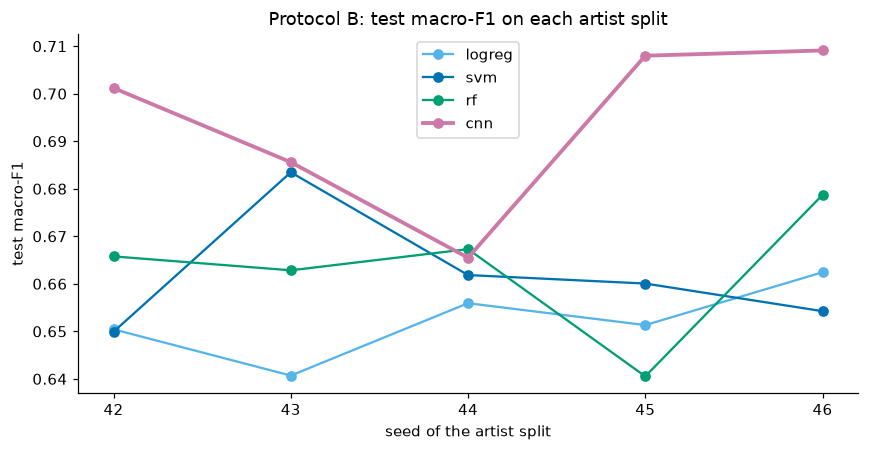

model,dummy,logreg,svm,rf,vote,cnn
protocol,,,,,,
B42,0.258,0.650,0.650,0.666,0.652,0.701
B43,0.244,0.641,0.683,0.663,0.665,0.686
B44,0.260,0.656,0.662,0.667,0.668,0.666
B45,0.270,0.651,0.660,0.641,0.665,0.708
B46,0.262,0.662,0.654,0.679,0.669,0.709


In [4]:
per_split = long_b.pivot(index="protocol", columns="model", values="test_macro_f1")[order]
per_split.round(4).to_csv(OUT / "02_protocol_B_per_split.csv")
fig, ax = plt.subplots(figsize=(8, 4.2))
for m in ["logreg", "svm", "rf", "cnn"]:
    ax.plot(per_split.index.str[1:], per_split[m], marker="o", color=COLORS[m], label=m, linewidth=2.5 if m == "cnn" else 1.5)
ax.set_xlabel("seed of the artist split")
ax.set_ylabel("test macro-F1")
ax.set_title("Protocol B: test macro-F1 on each artist split")
ax.legend()
save(fig, "02_protocol_B_per_split")
per_split.round(3)

**Paired differences.** For each split, the CNN score minus the score of a classical model on exactly the same test songs. A positive mean with a small standard deviation and a positive sign on most splits means a consistent advantage; a mean close to the standard deviation means the advantage depends on which artists are tested.

In [5]:
diff = pd.DataFrame({m: per_split["cnn"] - per_split[m] for m in ["logreg", "svm", "rf", "vote"]})
diff_summary = diff.agg(["mean", "std", "min", "max"]).T.assign(cnn_better=(diff > 0).sum(), splits=len(diff))
diff_summary.round(4).to_csv(OUT / "02_cnn_minus_classic.csv")
summary["cnn_minus"] = diff_summary["mean"].round(4).to_dict()
diff_summary.round(3)

,mean,std,min,max,cnn_better,splits
logreg,0.042,0.019,0.010,0.057,5,5
svm,0.032,0.027,0.002,0.055,5,5
rf,0.031,0.025,-0.002,0.067,4,5
vote,0.030,0.021,-0.003,0.049,4,5


## 3. Statistical test: McNemar, split by split

The exact McNemar test (decision D14) compares two models on the same test songs, using only the songs on which they disagree: *only_cnn_correct* songs the CNN gets right and the other model wrong, *only_other_correct* the opposite. It is run separately on protocol A and on each artist split.

In [6]:
def mcnemar(frame, left, right):
    l = frame[frame.model == left].set_index("Song")
    r = frame[frame.model == right].set_index("Song").loc[l.index]
    ok_l, ok_r = l["pred"] == l["true"], r["pred"] == r["true"]
    b_, c_ = int((ok_l & ~ok_r).sum()), int((~ok_l & ok_r).sum())
    return b_, c_, (stats.binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0)


rows = []
for protocol in ["A"] + done:
    frame = all_preds[all_preds.protocol == protocol]
    for other in ["logreg", "svm", "rf", "vote"]:
        b_, c_, p = mcnemar(frame, "cnn", other)
        rows.append({"protocol": protocol, "other": other, "only_cnn_correct": b_, "only_other_correct": c_, "p_value": p})
mc = pd.DataFrame(rows)
mc.round(4).to_csv(OUT / "03_mcnemar_cnn.csv", index=False)
mc_summary = mc[mc.protocol != "A"].groupby("other").agg(splits=("p_value", "size"), significant=("p_value", lambda s: int((s < 0.05).sum())),
                                                         cnn_wins_more=("only_cnn_correct", lambda s: 0)).copy()
mc_summary["cnn_wins_more"] = mc[mc.protocol != "A"].assign(w=lambda d: d.only_cnn_correct > d.only_other_correct).groupby("other")["w"].sum()
mc_summary.to_csv(OUT / "03_mcnemar_cnn_summary.csv")
summary["mcnemar_B_significant"] = mc_summary["significant"].to_dict()
display(mc.pivot(index="other", columns="protocol", values="p_value").round(3))
mc_summary

protocol,A,B42,B43,B44,B45,B46
other,,,,,,
logreg,0.152,0.026,0.077,0.731,0.031,0.067
rf,0.090,0.114,0.403,1.000,0.009,0.267
svm,0.654,0.031,1.000,1.000,0.072,0.040
vote,0.371,0.032,0.448,0.929,0.122,0.149


,splits,significant,cnn_wins_more
other,,,
logreg,5,2,5
rf,5,1,4
svm,5,2,5
vote,5,1,4


**Pooled over the artist splits.** Each split alone has about 460 test songs, which limits the power of the test. Because the five test sets contain different artists, their disagreements can be summed and tested once more. Songs that appear in several test sets are counted once per split, so this pooled test is somewhat optimistic and is reported as a complement, not as the main result.

In [7]:
pooled = mc[mc.protocol != "A"].groupby("other")[["only_cnn_correct", "only_other_correct"]].sum()
pooled["p_value"] = [stats.binomtest(int(b_), int(b_ + c_), 0.5).pvalue for b_, c_ in zip(pooled.only_cnn_correct, pooled.only_other_correct)]
pooled.round(4).to_csv(OUT / "03_mcnemar_pooled_B.csv")
summary["mcnemar_pooled_p"] = pooled["p_value"].round(4).to_dict()
pooled.round(4)

,only_cnn_correct,only_other_correct,p_value
other,,,
logreg,361,264,0.0001
rf,326,258,0.0055
svm,339,268,0.0045
vote,324,259,0.0080


## 4. Where does the difference come from? Per-quadrant F1

**Purpose:** a better overall score can come from any quadrant. Here the per-class F1 is averaged over the artist splits for the CNN and the two main classical models.

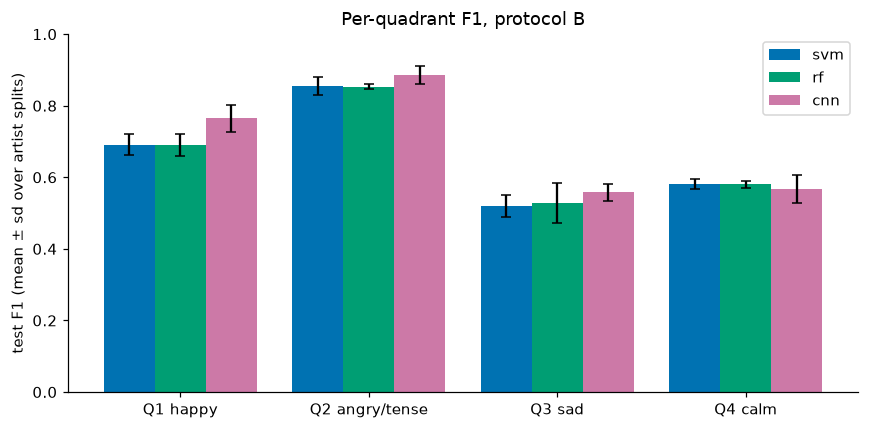

test_f1_Q1        test_f1_Q2        test_f1_Q3        test_f1_Q4       
            mean    std       mean    std       mean    std       mean    std
model                                                                        
cnn        0.765  0.037      0.886  0.024      0.558  0.023      0.567  0.040
rf         0.691  0.031      0.853  0.007      0.527  0.056      0.580  0.010
svm        0.691  0.029      0.855  0.024      0.520  0.032      0.582  0.015

In [8]:
pc = long_b[long_b.model.isin(["svm", "rf", "cnn"])].groupby("model")[[f"test_f1_{q}" for q in QUADRANTS]].agg(["mean", "std"])
pc.round(3).to_csv(OUT / "04_per_class_f1_B.csv")
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(4)
for k, m in enumerate(["svm", "rf", "cnn"]):
    ax.bar(x + (k - 1) * 0.27, [pc.loc[m, (f"test_f1_{q}", "mean")] for q in QUADRANTS], 0.27,
           yerr=[pc.loc[m, (f"test_f1_{q}", "std")] for q in QUADRANTS], capsize=3, color=COLORS[m], label=m)
ax.set_xticks(x, [NAMES[q] for q in QUADRANTS])
ax.set_ylabel("test F1 (mean ± sd over artist splits)")
ax.set_ylim(0, 1)
ax.legend()
ax.set_title("Per-quadrant F1, protocol B")
save(fig, "04_per_class_f1_B")
pc.round(3)

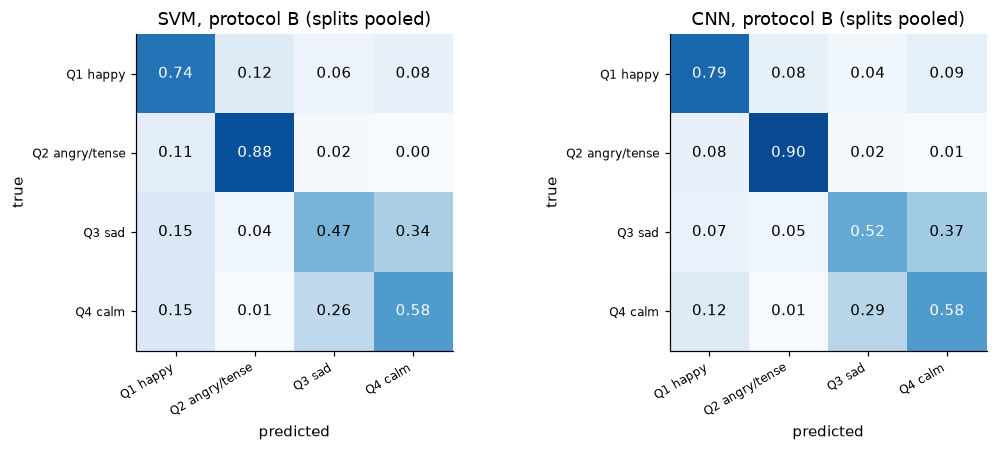

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
pool = all_preds[all_preds.protocol.isin(done)]
for ax, m in zip(axes, ["svm", "cnn"]):
    s = pool[pool.model == m]
    cm = confusion_matrix(s["true"], s["pred"], labels=QUADRANTS, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(4), [NAMES[q] for q in QUADRANTS], rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(4), [NAMES[q] for q in QUADRANTS], fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{m.upper()}, protocol B (splits pooled)")
save(fig, "04_confusion_svm_vs_cnn")

## 5. Q3/Q4 by genre: does the CNN fix the weak spot?

The same breakdown as in `04_classic_experiments.ipynb` §9, now for the CNN next to the SVM: share of Q3 and Q4 test songs classified as the other low-arousal quadrant, by main genre (first genre in the metadata column `Genres`), pooled over the artist splits.

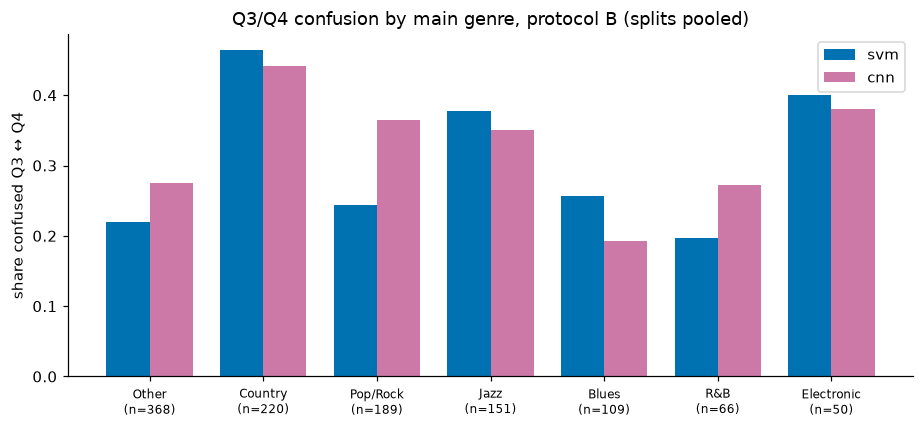

mean        size     
model         cnn    svm  cnn  svm
Genre                             
Other       0.274  0.220  368  368
Country     0.441  0.464  220  220
Pop/Rock    0.365  0.243  189  189
Jazz        0.351  0.377  151  151
Blues       0.193  0.257  109  109
R&B         0.273  0.197   66   66
Electronic  0.380  0.400   50   50

In [10]:
meta = pd.read_csv(META, usecols=["Song", "Genres"], dtype={"Song": str})
meta["MainGenre"] = meta["Genres"].fillna("Unknown").str.split(",").str[0]
low = pool[pool.true.isin(["Q3", "Q4"]) & pool.model.isin(["svm", "cnn"])].merge(meta, on="Song")
low["confused"] = low["pred"].isin(["Q3", "Q4"]) & (low["pred"] != low["true"])
top = low[low.model == "svm"]["MainGenre"].value_counts().head(6).index
low["Genre"] = np.where(low["MainGenre"].isin(top), low["MainGenre"], "Other")
g = low.groupby(["Genre", "model"])["confused"].agg(["mean", "size"]).unstack("model")
g = g.sort_values(("size", "svm"), ascending=False)
g.round(3).to_csv(OUT / "05_q3_q4_by_genre.csv")
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(g))
for k, m in enumerate(["svm", "cnn"]):
    ax.bar(x + (k - 0.5) * 0.38, g[("mean", m)], 0.38, color=COLORS[m], label=m)
ax.set_xticks(x, [f"{i}\n(n={int(n)})" for i, n in zip(g.index, g[("size", "svm")])], fontsize=8)
ax.set_ylabel("share confused Q3 ↔ Q4")
ax.set_title("Q3/Q4 confusion by main genre, protocol B (splits pooled)")
ax.legend()
save(fig, "05_q3_q4_by_genre")
summary["q3q4_rate"] = low.groupby("model")["confused"].mean().round(3).to_dict()
g.round(3)

## 6. Do the two families make the same errors?

If the CNN and the SVM were wrong on the same songs, they would capture the same information. The table counts, over the pooled artist splits, the songs both get right, only one gets right, and neither gets right. A large share of songs that only one of them gets right means the representations are complementary, which is a possible direction for future work (combining spectrogram and hand-crafted features), not something tested here.

In [11]:
pair = pool[pool.model.isin(["svm", "cnn"])].assign(ok=lambda d: d.pred == d.true).pivot_table(index=["protocol", "Song"], columns="model", values="ok", aggfunc="first")
agree = pd.crosstab(pair["cnn"], pair["svm"], rownames=["CNN correct"], colnames=["SVM correct"], margins=True)
agree.to_csv(OUT / "06_agreement_cnn_svm.csv")
summary["only_one_correct_share"] = round(float((pair["cnn"] != pair["svm"]).mean()), 3)
agree

SVM correct,False,True,All
CNN correct,,,
False,429,268,697
True,339,1274,1613
All,768,1542,2310


## 7. Training curves of the CNN

**Purpose:** show that training behaved well on every split: training loss decreasing, validation loss not diverging, and the selected epoch (marker) not at the very first epochs. Validation macro-F1 fluctuates between epochs, which is why the best epoch is chosen on validation and why differences of about 0.02 between single runs are not interpreted.

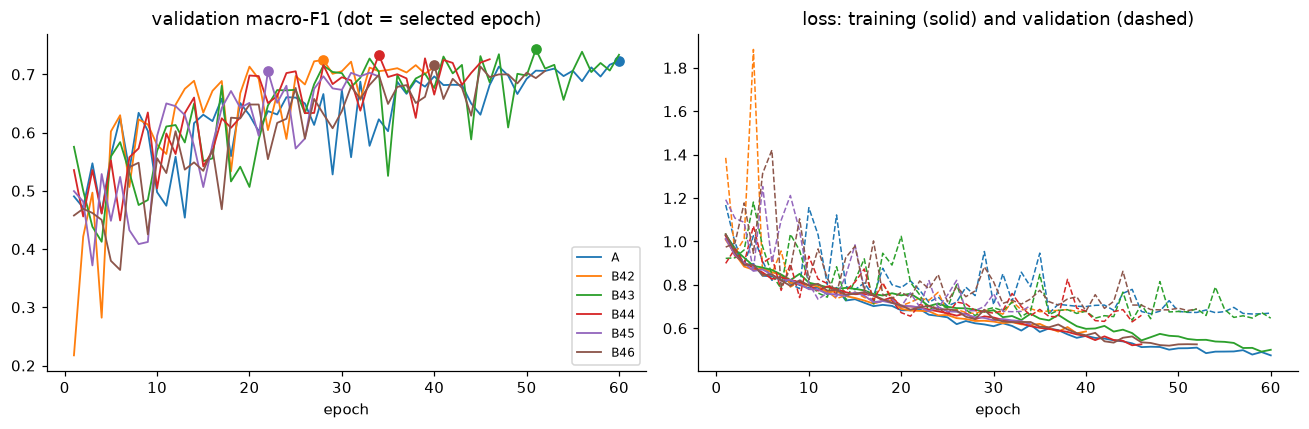

,protocol,best_epoch,epochs_run,train_macro_f1,val_macro_f1,test_macro_f1
0,A,60,60,0.844,0.723,0.682
3,B42,28,40,0.765,0.725,0.701
4,B43,51,60,0.804,0.743,0.686
5,B44,34,46,0.788,0.734,0.666
6,B45,22,34,0.739,0.705,0.708
7,B46,40,52,0.800,0.716,0.709


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r in cnn[cnn.config == "small"].itertuples():
    h = pd.read_csv(CNN_DIR / r.folder / "history.csv")
    line, = axes[0].plot(h.epoch, h.val_macro_f1, label=r.protocol, linewidth=1.2)
    axes[0].plot(r.best_epoch, h.loc[h.epoch == r.best_epoch, "val_macro_f1"], "o", color=line.get_color())
    axes[1].plot(h.epoch, h.train_loss, color=line.get_color(), linewidth=1.2)
    axes[1].plot(h.epoch, h.val_loss, color=line.get_color(), linestyle="--", linewidth=1)
axes[0].set_title("validation macro-F1 (dot = selected epoch)")
axes[0].set_xlabel("epoch")
axes[0].legend(fontsize=8)
axes[1].set_title("loss: training (solid) and validation (dashed)")
axes[1].set_xlabel("epoch")
save(fig, "07_training_curves")
cnn[cnn.config == "small"][["protocol", "best_epoch", "epochs_run", "train_macro_f1", "val_macro_f1", "test_macro_f1"]].round(3)

## 8. Cost

The CNN needs Mel-spectrograms (computed once, D16) and hours of training on the laptop CPU; the classical models need hand-crafted features (computed once) and seconds of training. Model size matters for the interface.

In [13]:
cost = pd.DataFrame({
    "parameters_or_inputs": ["155 features", "155 features", f"{int(cnn.loc[cnn.config == 'small', 'parameters'].iloc[0]):,} weights"],
    "train_seconds_mean": [classic[(classic.model == "svm") & classic.protocol.isin(done)]["fit_seconds"].mean(),
                           classic[(classic.model == "rf") & classic.protocol.isin(done)]["fit_seconds"].mean(),
                           cnn[(cnn.config == "small") & cnn.protocol.isin(done)]["train_seconds"].mean()],
    "model_MB": [classic[(classic.model == "svm") & classic.protocol.isin(done)]["model_bytes"].mean() / 1e6,
                 classic[(classic.model == "rf") & classic.protocol.isin(done)]["model_bytes"].mean() / 1e6,
                 cnn[(cnn.config == "small") & cnn.protocol.isin(done)]["model_mb"].mean()],
}, index=["svm", "rf", "cnn"])
cost.round(2).to_csv(OUT / "08_cost.csv")
cost.round(2)

,parameters_or_inputs,train_seconds_mean,model_MB
svm,155 features,0.51,2.44
rf,155 features,3.88,28.56
cnn,"294,228 weights",7243.84,1.20


## 9. Comparison with the published baseline

The authors of MERGE report, for **MERGE Audio Balanced** with the official **70-15-15** split (our protocol A), an F1-score of **68.52 %** for hand-crafted features with an SVM and **66.75 %** for a deep model on wav2vec2 embeddings (Louro et al., *MERGE — A Bimodal Audio-Lyrics Dataset for Static Music Emotion Recognition*, IEEE Transactions on Affective Computing, 2026, Table III). Their deep model is not a CNN on Mel-spectrograms and their hand-crafted feature set is much larger than ours, so the comparison is about the level reached, not about identical methods. The paper reports no results on artist-grouped splits, so protocol B has no published counterpart.

In [14]:
published = pd.DataFrame({"published (Louro et al., 2026)": [68.52, 66.75], "this work": [
    100 * classic[(classic.protocol == "A") & (classic.model == "svm")]["test_macro_f1"].iloc[0],
    100 * cnn[(cnn.config == "small") & (cnn.protocol == "A")]["test_macro_f1"].iloc[0]]},
    index=["hand-crafted features + SVM", "deep learning (theirs: wav2vec2 + DNN; ours: CNN on Mel-spectrograms)"])
published.round(2).to_csv(OUT / "09_published_comparison.csv")
published.round(2)

,"published (Louro et al., 2026)",this work
hand-crafted features + SVM,68.52,67.10
deep learning (theirs: wav2vec2 + DNN; ours: CNN on Mel-spectrograms),66.75,68.16


## 10. Summary of the numbers used in the findings

In [15]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
summary

{'cnn_B_splits_available': ['B42', 'B43', 'B44', 'B45', 'B46'],
 'B_mean': {'dummy': 0.2587,
  'logreg': 0.6522,
  'svm': 0.6619,
  'rf': 0.663,
  'vote': 0.6642,
  'cnn': 0.6939},
 'B_sd': {'dummy': 0.0095,
  'logreg': 0.008,
  'svm': 0.013,
  'rf': 0.0139,
  'vote': 0.0069,
  'cnn': 0.0184},
 'cnn_minus': {'logreg': 0.0417, 'svm': 0.032, 'rf': 0.0308, 'vote': 0.0297},
 'mcnemar_B_significant': {'logreg': 2, 'rf': 1, 'svm': 2, 'vote': 1},
 'mcnemar_pooled_p': {'logreg': 0.0001,
  'rf': 0.0055,
  'svm': 0.0045,
  'vote': 0.008},
 'q3q4_rate': {'cnn': 0.328, 'svm': 0.301},
 'only_one_correct_share': 0.263}

## 11. Findings

Numbers below come from the tables above. *Protocol B* means mean ± standard deviation over the five artist-grouped splits (B42–B46).

**1. On unseen artists the CNN is the best model, by about three points.** Test macro-F1 on protocol B: CNN 0.694 ± 0.018, against 0.662 ± 0.013 for the SVM, 0.663 ± 0.014 for the Random Forest, 0.664 ± 0.007 for the vote and 0.652 ± 0.008 for logistic regression (chance level 0.259 ± 0.010). Accuracy follows the same pattern (CNN 69.8 %, SVM 66.8 %).

**2. The advantage is consistent in sign but varies in size.** The CNN beats the SVM on all five splits (by +0.032 ± 0.027 on average, from +0.002 on B44 to +0.055 on B45) and the Random Forest on four of five (+0.031 ± 0.025; −0.002 on B44). The variation of the gap between splits is of the same order as the gap itself, which is why a single split would not have been enough to conclude.

**3. The difference is statistically significant when the splits are taken together, not on each split alone.** McNemar's test is significant against the SVM on two of the five splits (B42, p = 0.031; B46, p = 0.040) and against the Random Forest on one (B45, p = 0.009); on the other splits the CNN still wins more of the disagreements in all but one comparison with the Random Forest. Pooled over the five splits, the CNN is right where the SVM is wrong on 339 songs and the opposite happens on 268 (p = 0.0045); against the Random Forest the counts are 326 and 258 (p = 0.0055). Because some songs appear in several test sets, the pooled p-values are somewhat optimistic; the conclusion that the CNN is better on average is supported by both the consistent sign and the pooled test.

**4. On the official split the difference is not significant.** On protocol A the chosen CNN scores 0.682 against 0.671 for the SVM (McNemar p = 0.65). Protocol A is a single split, and the protocol-B results show that one split can show a gap anywhere between 0.00 and 0.06.

**5. The gain comes mainly from the high-arousal quadrants; Q3/Q4 is not solved.** Mean per-class F1 on protocol B, CNN against SVM: Q1 0.765 vs 0.691, Q2 0.886 vs 0.855, Q3 0.558 vs 0.520, Q4 0.567 vs 0.582. The CNN confuses sad and calm songs slightly more often than the SVM (75.6 against 69.4 confusions per split; 32.8 % against 30.1 % of the Q3/Q4 test songs). By genre, the CNN is not better on the hardest genres (Country 44 % vs 46 %, Jazz 35 % vs 38 %), is better on Blues (19 % vs 26 %) and worse on Pop/Rock (37 % vs 24 %). Learning from the spectrogram does not supply the missing valence information, consistent with `05_spectrograms.ipynb`, where the average spectra of Q3 and Q4 differ by less than half a decibel.

**6. The two families make different errors.** Over the pooled artist splits, 26.3 % of the test songs are classified correctly by exactly one of the two models (339 only by the CNN, 268 only by the SVM), while 18.6 % are missed by both. Spectrogram-based and feature-based models therefore capture partly different information, which makes a combination of the two worth testing (next step, chosen on validation).

**7. Training behaved well on every split.** The selected epoch lies between 22 and 51 on the artist splits (training stopped early on all but B43), and the gap between training and validation macro-F1 is 0.03–0.08, so the network learns general patterns rather than memorising the training songs. On protocol A training ran the full 60 epochs, with the learning rate already reduced 64 times by the end.

**8. The CNN is far more expensive to train, but not to keep.** Training takes about two hours per split on the laptop CPU (7,244 s on average) against half a second for the SVM; the trained CNN, however, is the smallest model (1.2 MB, against 2.4 MB for the SVM and 28.6 MB for the Random Forest).

**9. The results are at the level of the published baseline.** On the official 70-15-15 split of MERGE Audio Balanced, our SVM reaches 67.10 % against 68.52 % reported by the dataset authors for hand-crafted features with an SVM, and our CNN 68.16 % against 66.75 % for their wav2vec2-based deep model. Differences of one to two points on a single split are within the variation measured here, so the honest conclusion is that both pipelines perform at the published level. The paper reports no artist-grouped evaluation, so the protocol-B results have no published counterpart.

**Answer to the main question.** Evaluated on artists unseen during training, a small CNN trained from scratch on Mel-spectrograms recognises the four emotion quadrants better than SVM and Random Forest on 155 hand-crafted features, by about three points of macro-F1 on average; the advantage is consistent in sign, significant over the five splits together, and comes from the high-arousal quadrants. Neither approach resolves the confusion between sad and calm music.